In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [1]:
class Perceptron:
    def __init__(self, n_inputs, lr=0.1, epochs=100, seed=42):
        rng = np.random.default_rng(seed)
        self.w = rng.uniform(-0.5, 0.5, n_inputs)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.history = []
        self.converged_at = None

    @staticmethod
    def activation(z):
        return 1 if z >= 0 else 0

    def predict_one(self, x):
        return self.activation(np.dot(self.w, x) + self.b)

    def predict(self, X):
        return np.array([self.predict_one(x) for x in X])

    def fit(self, X, y):
        for epoch in range(1, self.epochs + 1):
            errors = 0
            for xi, target in zip(X, y):
                out = self.predict_one(xi)
                err = target - out
                if err != 0:
                    self.w = self.w + self.lr * err * xi
                    self.b = self.b + self.lr * err
                    errors += 1
            self.history.append((epoch, self.w.copy(), self.b, errors))
            if errors == 0 and self.converged_at is None:
                self.converged_at = epoch
                break
        return self

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == y) * 100

In [4]:
X = np.array([[0,0],[0,1],[1,0],[1,1]])

gates = {
    "AND":  np.array([0,0,0,1]),
    "OR":   np.array([0,1,1,1]),
    "NAND": np.array([1,1,1,0]),
    "XOR":  np.array([0,1,1,0]),
}

print("Input patterns:\n", X)
print("\nTruth tables (targets):")
print(pd.DataFrame({"x1":X[:,0], "x2":X[:,1], **gates}).to_string(index=False))

Input patterns:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]

Truth tables (targets):
 x1  x2  AND  OR  NAND  XOR
  0   0    0   0     1    0
  0   1    0   1     1    1
  1   0    0   1     1    1
  1   1    1   1     0    0


##Question 1

In [5]:
models = {}
summary = []

for name in ["AND", "OR", "NAND"]:
    y = gates[name]
    p = Perceptron(n_inputs=2, lr=0.1, epochs=100).fit(X, y)
    models[name] = p
    pred = p.predict(X)
    acc = p.accuracy(X, y)

    print("="*55)
    print(f"{name} GATE")
    print(f"Final weights : {np.round(p.w, 3)}")
    print(f"Final bias    : {round(p.b, 3)}")
    print(f"Converged at epoch: {p.converged_at}")
    print(pd.DataFrame({"x1":X[:,0], "x2":X[:,1], "Actual":y, "Predicted":pred,
                        "Correct":np.where(pred==y, "Yes", "No")}).to_string(index=False))
    print(f"Accuracy: {acc:.1f}%")
    summary.append((name, "Yes", p.converged_at, acc))

AND GATE
Final weights : [0.174 0.039]
Final bias    : -0.2
Converged at epoch: 3
 x1  x2  Actual  Predicted Correct
  0   0       0          0     Yes
  0   1       0          0     Yes
  1   0       0          0     Yes
  1   1       1          1     Yes
Accuracy: 100.0%
OR GATE
Final weights : [0.274 0.139]
Final bias    : -0.1
Converged at epoch: 4
 x1  x2  Actual  Predicted Correct
  0   0       0          0     Yes
  0   1       1          1     Yes
  1   0       1          1     Yes
  1   1       1          1     Yes
Accuracy: 100.0%
NAND GATE
Final weights : [-0.226 -0.161]
Final bias    : 0.3
Converged at epoch: 11
 x1  x2  Actual  Predicted Correct
  0   0       1          1     Yes
  0   1       1          1     Yes
  1   0       1          1     Yes
  1   1       0          0     Yes
Accuracy: 100.0%


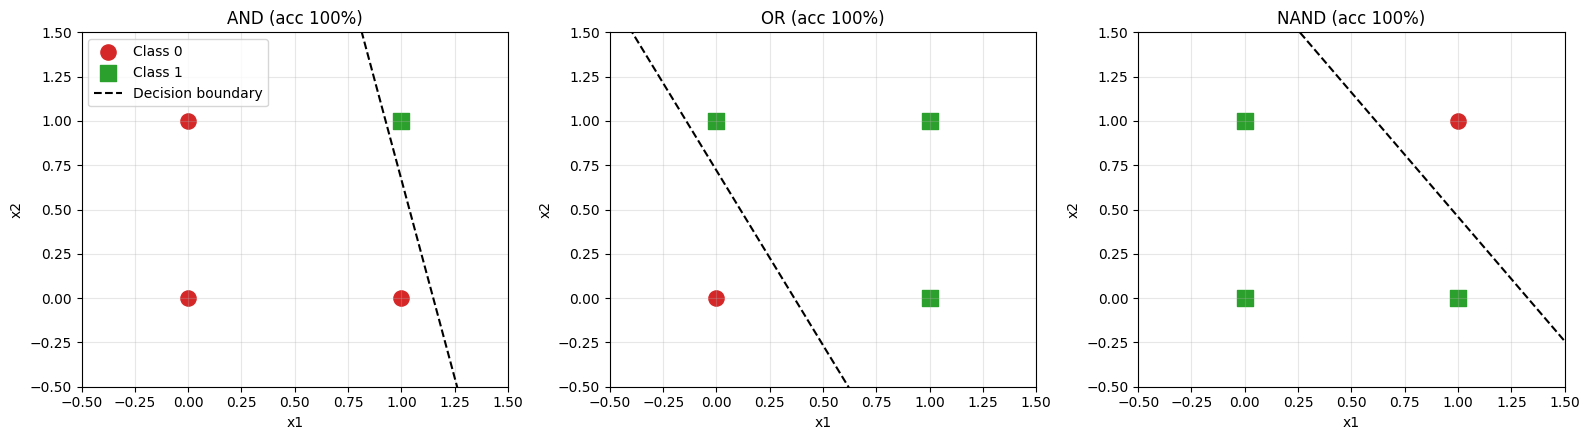

In [6]:
def plot_boundary(ax, p, X, y, title):
    for cls, marker, col in [(0, 'o', 'tab:red'), (1, 's', 'tab:green')]:
        ax.scatter(X[y==cls,0], X[y==cls,1], marker=marker, s=120, c=col, label=f'Class {cls}')
    xs = np.linspace(-0.5, 1.5, 100)
    if abs(p.w[1]) > 1e-9:
        ax.plot(xs, -(p.w[0]*xs + p.b)/p.w[1], 'k--', label='Decision boundary')
    ax.set_xlim(-0.5,1.5); ax.set_ylim(-0.5,1.5)
    ax.set_title(title); ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.grid(alpha=.3)

fig, axes = plt.subplots(1, 3, figsize=(16,4.5))
for ax, name in zip(axes, ["AND","OR","NAND"]):
    plot_boundary(ax, models[name], X, gates[name], f"{name} (acc {models[name].accuracy(X, gates[name]):.0f}%)")
axes[0].legend()
plt.tight_layout(); plt.show()

##Question 2.

In [7]:
y_xor = gates["XOR"]
xor = Perceptron(n_inputs=2, lr=0.1, epochs=50)
xor.fit(X, y_xor)

print("Weight updates across epochs (first 10 and last 3):")
rows = [(e, np.round(w,3), round(b,3), err) for e, w, b, err in xor.history]
df_hist = pd.DataFrame(rows, columns=["Epoch","Weights","Bias","Misclassified"])
print(pd.concat([df_hist.head(10), df_hist.tail(3)]).to_string(index=False))

pred_xor = xor.predict(X)
print("\nFinal weights:", np.round(xor.w,3), "| Final bias:", round(xor.b,3))
print(pd.DataFrame({"x1":X[:,0], "x2":X[:,1], "Actual":y_xor, "Predicted":pred_xor}).to_string(index=False))
print(f"\nXOR Accuracy: {xor.accuracy(X, y_xor):.1f}%")
print("Converged at epoch:", xor.converged_at)
summary.append(("XOR", "No", xor.converged_at, xor.accuracy(X, y_xor)))

Weight updates across epochs (first 10 and last 3):
 Epoch          Weights  Bias  Misclassified
     1  [0.174, -0.061]  -0.1              3
     2  [0.074, -0.061]  -0.1              2
     3 [-0.026, -0.061]  -0.1              2
     4 [-0.026, -0.061]   0.0              3
     5 [-0.026, -0.061]   0.0              4
     6 [-0.026, -0.061]   0.0              4
     7 [-0.026, -0.061]   0.0              4
     8 [-0.026, -0.061]   0.0              4
     9 [-0.026, -0.061]   0.0              4
    10 [-0.026, -0.061]   0.0              4
    48 [-0.026, -0.061]   0.0              4
    49 [-0.026, -0.061]   0.0              4
    50 [-0.026, -0.061]   0.0              4

Final weights: [-0.026 -0.061] | Final bias: 0.0
 x1  x2  Actual  Predicted
  0   0       0          1
  0   1       1          0
  1   0       1          0
  1   1       0          0

XOR Accuracy: 25.0%
Converged at epoch: None


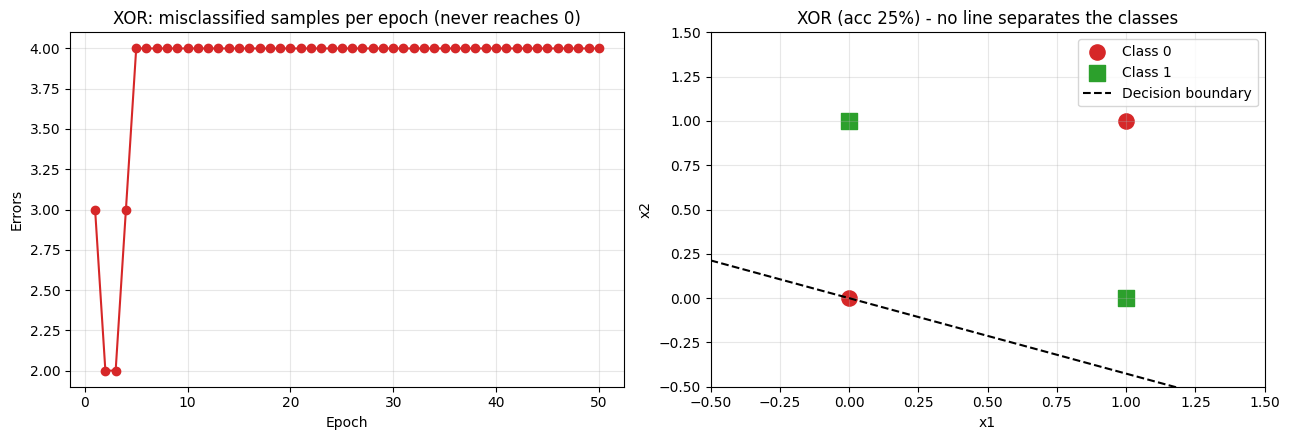

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))

# Misclassifications per epoch
axes[0].plot([h[0] for h in xor.history], [h[3] for h in xor.history], marker='o', color='tab:red')
axes[0].set_title("XOR: misclassified samples per epoch (never reaches 0)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Errors"); axes[0].grid(alpha=.3)

# Decision boundary
plot_boundary(axes[1], xor, X, y_xor, f"XOR (acc {xor.accuracy(X, y_xor):.0f}%) - no line separates the classes")
axes[1].legend()
plt.tight_layout(); plt.show()

In [9]:
cmp = pd.DataFrame(summary, columns=["Logic Gate", "Linearly Separable", "Converged at Epoch", "Accuracy (%)"])
cmp["SLP Learning Outcome"] = np.where(cmp["Accuracy (%)"] == 100, "Converges", "Does not converge to a perfect solution")
cmp["Converged at Epoch"] = cmp["Converged at Epoch"].fillna("Never")
cmp

,Logic Gate,Linearly Separable,Converged at Epoch,Accuracy (%),SLP Learning Outcome
0,AND,Yes,3.0,100.0,Converges
1,OR,Yes,4.0,100.0,Converges
2,NAND,Yes,11.0,100.0,Converges
3,XOR,No,Never,25.0,Does not converge to a perfect solution


##Question 3.

In [10]:
df_a = pd.DataFrame({
    "Student": [f"S{i}" for i in range(1, 9)],
    "Internal Assessment": [85, 75, 65, 45, 50, 30, 90, 40],
    "Attendance (%)":      [90, 85, 80, 60, 55, 45, 95, 50],
    "Scholarship Eligibility": [1, 1, 1, 0, 0, 0, 1, 0],
})
display(df_a)

Xa_raw = df_a[["Internal Assessment", "Attendance (%)"]].values.astype(float)
ya = df_a["Scholarship Eligibility"].values

mn, mx = Xa_raw.min(axis=0), Xa_raw.max(axis=0)
Xa = (Xa_raw - mn) / (mx - mn)

perc_a = Perceptron(n_inputs=2, lr=0.1, epochs=200).fit(Xa, ya)
pred_a = perc_a.predict(Xa)

print("Weights:", np.round(perc_a.w, 3), "| Bias:", round(perc_a.b, 3))
print("Converged at epoch:", perc_a.converged_at)
print("Accuracy:", perc_a.accuracy(Xa, ya), "%")
df_a["Predicted"] = pred_a
display(df_a)

,Student,Internal Assessment,Attendance (%),Scholarship Eligibility
0,S1,85,90,1
1,S2,75,85,1
2,S3,65,80,1
3,S4,45,60,0
4,S5,50,55,0
5,S6,30,45,0
6,S7,90,95,1
7,S8,40,50,0


Weights: [ 0.282 -0.051] | Bias: -0.1
Converged at epoch: 3
Accuracy: 100.0 %


,Student,Internal Assessment,Attendance (%),Scholarship Eligibility,Predicted
0,S1,85,90,1,1
1,S2,75,85,1,1
2,S3,65,80,1,1
3,S4,45,60,0,0
4,S5,50,55,0,0
5,S6,30,45,0,0
6,S7,90,95,1,1
7,S8,40,50,0,0


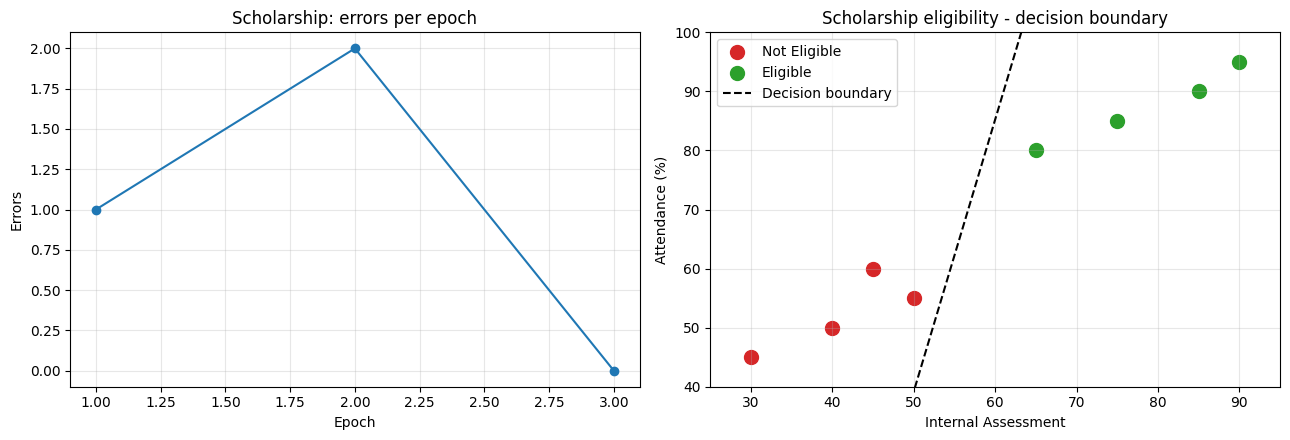

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot([h[0] for h in perc_a.history], [h[3] for h in perc_a.history], marker='o')
axes[0].set_title("Scholarship: errors per epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Errors"); axes[0].grid(alpha=.3)

for cls, col, lab in [(0,'tab:red','Not Eligible'), (1,'tab:green','Eligible')]:
    axes[1].scatter(Xa_raw[ya==cls,0], Xa_raw[ya==cls,1], c=col, s=100, label=lab)

xs_s = np.linspace(0, 1, 100)
ys_s = -(perc_a.w[0]*xs_s + perc_a.b)/perc_a.w[1]
axes[1].plot(xs_s*(mx[0]-mn[0])+mn[0], ys_s*(mx[1]-mn[1])+mn[1], 'k--', label='Decision boundary')
axes[1].set_xlim(Xa_raw[:,0].min()-5, Xa_raw[:,0].max()+5); axes[1].set_ylim(Xa_raw[:,1].min()-5, Xa_raw[:,1].max()+5)
axes[1].set_xlabel("Internal Assessment"); axes[1].set_ylabel("Attendance (%)")
axes[1].set_title("Scholarship eligibility - decision boundary"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [12]:
df_b = pd.DataFrame({
    "Candidate": [f"C{i}" for i in range(1, 9)],
    "Technical Test": [1,1,0,0,1,0,1,0],
    "Interview":      [1,0,1,0,1,0,0,1],
    "Selection":      [1,1,1,0,1,0,1,1],
})
Xb = df_b[["Technical Test", "Interview"]].values
yb = df_b["Selection"].values

perc_b = Perceptron(n_inputs=2, lr=0.1, epochs=100).fit(Xb, yb)
df_b["Predicted"] = perc_b.predict(Xb)
display(df_b)
print("Weights:", np.round(perc_b.w, 3), "| Bias:", round(perc_b.b, 3))
print("Converged at epoch:", perc_b.converged_at, "| Accuracy:", perc_b.accuracy(Xb, yb), "%")

,Candidate,Technical Test,Interview,Selection,Predicted
0,C1,1,1,1,1
1,C2,1,0,1,1
2,C3,0,1,1,1
3,C4,0,0,0,0
4,C5,1,1,1,1
5,C6,0,0,0,0
6,C7,1,0,1,1
7,C8,0,1,1,1


Weights: [0.274 0.139] | Bias: -0.1
Converged at epoch: 3 | Accuracy: 100.0 %


## Conclusion
- AND, OR and NAND are **linearly separable**, so the perceptron converges to 100% accuracy in a few epochs.
- XOR is **not linearly separable**; the SLP cannot reach 100% accuracy and the error never settles at zero.
- The **weights** set the orientation of the decision boundary and the **bias** shifts it away from the origin.
- Real data (scholarship, selection) is learnable by an SLP when the classes are separable; feature scaling helps for real-valued inputs.
- Non-linearly separable problems such as XOR need a **Multi-Layer Perceptron** with hidden layers.